# 03 · The test, run once

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p05_when_to_stop/notebooks/03_the_test.ipynb)

**Project 5 — When to stop.** The rule was developed on the extremum-seeking batches of June–July
2021. The test batches come from a different optimiser (Bayesian optimisation), a different month
(October), and were scored once, by a script that refuses to run unless the declaration is committed
and unchanged. This notebook shows what came out — including what failed.

**Data:** a public closed-circuit reverse-osmosis (CCRO) testbed record, "Foundational Control Methods for Water Treatment Systems — Online Actuator and Sensor Data", [doi:10.7481/1963162](https://doi.org/10.7481/1963162), CC BY 4.0: 881 batch files from June to October 2021. The notebooks read the tables committed in `results/` and a 0.8 MB excerpt of five batch files; the 351 MB of zips are needed only where a cell says so.

Script version: `step3_ccro_rule_test.py` · record: `VALIDATION.md`, section 4 · declaration:
`DECLARED_BEFORE_RUN_A.md`.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 5 pull request is merged, use "p05-when-to-stop"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P5 = ROOT / "projects" / "p05_when_to_stop"
RES = P5 / "results"
sys.path.insert(0, str(P5))          # the step scripts, for the helpers they define

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, TEAL = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#0f7c8c"

def load(name):
    """A committed result file from projects/p05_when_to_stop/results/."""
    return json.loads((RES / name).read_text())

## 1. What was declared

The four tests, as written before the run (the full file says also what was seen of the test data
beforehand: median cost curves, printed during the audit; the rule itself was never run on them):

In [2]:
text = (P5 / "DECLARED_BEFORE_RUN_A.md").read_text()
start = text.index("**T1"); end = text.index("## What would count")
print(text[start:end])
test = load("step3_ccro_rule_test.json")
print("declaration commit recorded by the test run:", test["declaration_commit"][:7])

**T1 — the rule finds the best end (primary).** For b = 1 and for b = 10 separately, over batches
whose own best is inside: median regret ≤ **0.5 %** and 90th percentile ≤ **1.0 %**. b = 0 and 3 are
reported the same way. A b with fewer than 10 inside batches is reported as *too few*, not as pass or fail.

**T2 — it does not stop early when the cost is still falling.** Over batches whose own best is not
inside, for each b: the rule's stop costs more than 0.5 % above the batch's end in at most **10 %**
of them.

**T3 — the rule against the optimiser that ran the batches** (reported, no pass mark). For each BO
experiment at its own b (Exp1 b = 1; Exp2, Exp3A, Exp3B b = 10): the share of batches BO ended
while the cost was still falling; on inside batches, BO's regret against the rule's; over all its
batches, the mean J at BO's ends against the mean J at the rule's ends (where the rule would have
run past a batch's end, J at the end is used — a bound that favours BO). Fixed ends at 10, 15

## 2. T1, T2, T4 as run

In [3]:
rows = []
for b, v in test["by_b"].items():
    r = {"b": b, "batches": v["batches"], "inside": v["inside"]}
    if isinstance(v["T1"], dict):
        r.update({"T1 median %": v["T1"]["median_pct"], "T1 p90 %": v["T1"]["p90_pct"], "T1": "pass" if v["T1"]["pass"] else "FAIL"})
        r.update({"T4 abs. error %": v["T4"]["median_abs_error_pct"], "T4": "pass" if v["T4"]["pass"] else "FAIL"})
    r.update({"T2 costlier than end": v["T2"]["costlier_than_end_by_0.5pct"], "T2": "pass" if v["T2"]["pass"] else "FAIL"})
    rows.append(r)
pd.DataFrame(rows)

,b,batches,inside,T1 median %,T1 p90 %,T1,T4 abs. error %,T4,T2 costlier than end,T2
0,b=0,153,103,0.080,0.135,pass,4.313,pass,0,pass
1,b=1,153,97,0.069,0.112,pass,5.144,pass,0,pass
2,b=3,153,75,0.063,0.090,pass,7.461,pass,0,pass
3,b=10,153,10,0.019,0.061,pass,11.345,FAIL,0,pass


Text(0.0, 1.0, 'the rule on held-out batches (red: the declared median limit)')

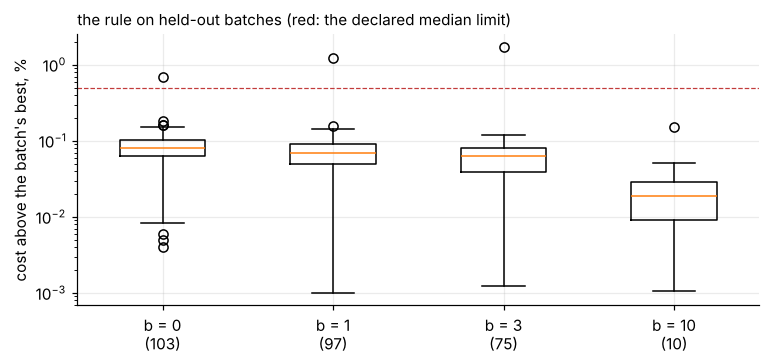

In [4]:
s = pd.read_parquet(RES / "step3_test_scores.parquet")
s = s[s.evaluable & s.constant_setpoints & s.inside]
fig, ax = plt.subplots(figsize=(8, 3.2))
data = [s[s.b == b].regret_rule_pct.clip(lower=1e-3) for b in (0, 1, 3, 10)]
ax.boxplot(data, tick_labels=[f"b = {b}\n({len(d)})" for b, d in zip((0, 1, 3, 10), data)], widths=0.5)
ax.set_yscale("log"); ax.axhline(0.5, color=RED, ls="--", lw=0.8)
ax.set_ylabel("cost above the batch's best, %")
ax.set_title("the rule on held-out batches (red: the declared median limit)", loc="left", fontsize=10)

**T1 and T2 pass at every brine price.** Half the batches ended within 0.02–0.08 % of their own best,
nine in ten within 0.06–0.14 %.

**T4 failed at b = 10.** The square-root law, fitted on minutes 5–20 of a batch, forecast the stop a
median 11 % short — the declared limit was 10 %. Why: the live cost is not quite straight.

b =  1: the law forecasts 115 L
b = 10: the law forecasts 201 L


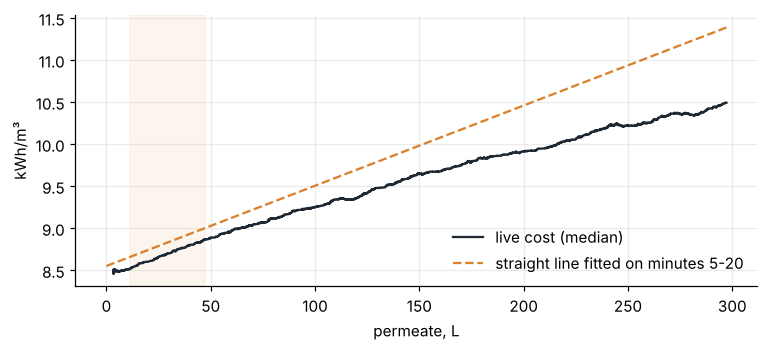

In [5]:
from chemai.config import CCROConfig
from chemai.features.ccro_batches import batch_curve, batch_table, sqrt_law_forecast
cfg = CCROConfig()
x = pd.read_parquet(RES / "excerpt_batches.parquet")
for c in ["permeate_conductivity_us_per_cm", "set_low_rej_cond_ms_per_cm"]:
    x[c] = np.nan
bo = x[x.dataset == "dataset6"]
row = batch_table(bo).set_index("seq").loc[11]
cv = batch_curve(bo[bo.seq == 11], cfg)
f = (cv.phase == "filt").to_numpy() & np.isfinite(cv.live_kwh_m3.to_numpy())
w = f & (cv.elapsed_min.to_numpy() >= 5) & (cv.elapsed_min.to_numpy() <= 20)
s_, m0 = np.polyfit(cv.V_m3[w], cv.live_kwh_m3[w], 1)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(cv.V_m3[f] * 1000, pd.Series(cv.live_kwh_m3[f]).rolling(240, min_periods=20).median(), color=INK, label="live cost (median)")
vv = np.linspace(0, cv.V_m3.max(), 50)
ax.plot(vv * 1000, m0 + s_ * vv, color=ORANGE, ls="--", label="straight line fitted on minutes 5-20")
ax.axvspan(cv.V_m3[w].min() * 1000, cv.V_m3[w].max() * 1000, color=ORANGE, alpha=0.08)
ax.set_xlabel("permeate, L"); ax.set_ylabel("kWh/m³"); ax.legend(frameon=False)
for b in (1, 10):
    law = sqrt_law_forecast(cv, row.prior_drain_kwh + b * row.prior_brine_l / 1000)
    print(f"b = {b:>2}: the law forecasts {law['V_star_l']:.0f} L")

Early in a batch the line rises a little faster than it does later; extrapolated far out, it
overstates the climb and forecasts the stop too soon. At b = 1 the stop is near and the error small;
at b = 10 it is far and the error crosses 10 %. The *online* rule never extrapolates — it compares
the live cost with the average as they happen — so it is unaffected. Stopping at the law's forecast
would still have cost only 0.15 % above the best.

## 3. Against the optimiser that ran the batches

In [6]:
pd.DataFrame(test["T3_against_BO"]).T[["b", "batches", "inside", "BO_ended_while_cost_still_falling",
                                         "mean_J_BO", "mean_J_rule_bound", "rule_vs_BO_mean_J_pct"]]

,b,batches,inside,BO_ended_while_cost_still_falling,mean_J_BO,mean_J_rule_bound,rule_vs_BO_mean_J_pct
Exp1,1.0,39,15,0.692,9.91,9.882,-0.28
Exp2,10.0,88,8,0.955,11.657,11.656,-0.013
Exp3A,10.0,17.0,0.0,1.0,13.202,13.202,0.0
Exp3B,10.0,9.0,0.0,1.0,11.472,11.472,0.0


BO ended 69 % of its b = 1 batches and 95–100 % of its b = 10 batches while their cost was still
falling. Where its batches did run past their best, its ends cost a median 0.52 % above the best at
b = 1; the rule's 0.06 %. The mean-cost column is a bound that favours BO: where BO stopped early, the
rule would have run on to a lower cost that the record does not show, and is charged BO's cost
instead.

A **fixed** end can do as well as the rule — if it was chosen for that brine price:

In [7]:
for e in ("Exp1", "Exp2"):
    print(e, test["T3_against_BO"][e]["fixed_end_regret_median_pct"])

Exp1 {'10 mS/cm': {'batches': 15, 'median': 3.837}, '15 mS/cm': {'batches': 15, 'median': 0.071}, '20 mS/cm': {'batches': 8, 'median': 0.414}, '25 mS/cm': {'batches': 2, 'median': 1.969}}
Exp2 {'10 mS/cm': {'batches': 8, 'median': 21.757}, '15 mS/cm': {'batches': 8, 'median': 4.539}, '20 mS/cm': {'batches': 8, 'median': 0.714}, '25 mS/cm': {'batches': 6, 'median': 0.019}}


15 mS/cm is nearly perfect at b = 1 and 4.5 % too early at b = 10; 25 mS/cm is the reverse. The rule
needs to know neither the price ahead of time nor the feed.

## 4. After the test: what this means at full scale

The testbed's pumps are its weak point: their marginal efficiency is about 12 %. Replace them with
80 % pumps and keep what the testbed measured about the loop (its osmotic slope, its volume, the brine
drained). The square-root law then gives the best permeate per batch as a multiple of the loop volume:

$$\frac{V^*}{V_{loop}} = \sqrt{\frac{72\,\beta\,\eta\, b}{k_\pi\, c_{feed}}}$$

Model-based, after the test, no pass mark:

In [8]:
fs = load("step6_ccro_full_scale.json")
print({k: fs[k] for k in ("k_pi_bar_per_ms_cm", "loop_volume_l", "beta_brine_over_loop", "testbed_marginal_efficiency")})
tab = pd.DataFrame(fs["full_scale"]["table"])
tab.pivot(index="feed_ms_cm", columns="b_kwh_per_m3_brine", values="batch_recovery")

{'k_pi_bar_per_ms_cm': 0.492, 'loop_volume_l': 20.3, 'beta_brine_over_loop': 0.8, 'testbed_marginal_efficiency': 0.122}


b_kwh_per_m3_brine,1.0,3.0,10.0,30.0
feed_ms_cm,,,,
1.0,0.923,0.954,0.974,0.985
2.0,0.895,0.937,0.964,0.979
3.5,0.866,0.918,0.953,0.972


At full-scale efficiency the energy-and-brine optimum lies at 87–99 % batch recovery — past where most
real brackish water starts to scale. In a real plant the scaling limit will usually end the batch;
on the testbed, its pumps made energy the larger term. What carries over is the rule itself: read
the plant's own live cost, and stop where it meets the average.